In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import os

print(os.getcwd())


d:\Movie Recommendation System\notebooks


In [6]:
movies = pd.read_csv("../data/movies.csv")
users = pd.read_csv("../data/users.csv")
ratings = pd.read_csv("../data/ratings.csv")

In [7]:
print("Movies shape:", movies.shape)
print("Users shape:", users.shape)
print("Ratings shape:", ratings.shape)

Movies shape: (3883, 3)
Users shape: (6040, 5)
Ratings shape: (1000209, 4)


In [8]:
print("MOVIES")
display(movies.head())

print("\nUSERS")
display(users.head())

print("\nRATINGS")
display(ratings.head())

MOVIES


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy



USERS


,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455



RATINGS


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [9]:
print("MOVIES")
movies.info()

print("\nUSERS")
users.info()

print("\nRATINGS")
ratings.info()

MOVIES
<class 'pandas.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   movie_id  3883 non-null   int64
 1   title     3883 non-null   str  
 2   genres    3883 non-null   str  
dtypes: int64(1), str(2)
memory usage: 91.1 KB

USERS
<class 'pandas.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     6040 non-null   int64
 1   gender      6040 non-null   str  
 2   age         6040 non-null   int64
 3   occupation  6040 non-null   int64
 4   zip_code    6040 non-null   str  
dtypes: int64(3), str(2)
memory usage: 236.1 KB

RATINGS
<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1000209 non-null  int64
 1   movie_id

In [10]:
print("Missing values in Movies:")
print(movies.isnull().sum())

print("\nMissing values in Users:")
print(users.isnull().sum())

print("\nMissing values in Ratings:")
print(ratings.isnull().sum())

Missing values in Movies:
movie_id    0
title       0
genres      0
dtype: int64

Missing values in Users:
user_id       0
gender        0
age           0
occupation    0
zip_code      0
dtype: int64

Missing values in Ratings:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64


In [11]:
print("Duplicate rows in Movies:", movies.duplicated().sum())
print("Duplicate rows in Users:", users.duplicated().sum())
print("Duplicate rows in Ratings:", ratings.duplicated().sum())

Duplicate rows in Movies: 0
Duplicate rows in Users: 0
Duplicate rows in Ratings: 0


In [12]:
print("Number of unique users:", ratings["user_id"].nunique())
print("Number of unique movies:", ratings["movie_id"].nunique())
print("Rating values:", sorted(ratings["rating"].unique()))

Number of unique users: 6040
Number of unique movies: 3706
Rating values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [13]:
rating_counts = ratings["rating"].value_counts().sort_index()

print(rating_counts)

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64


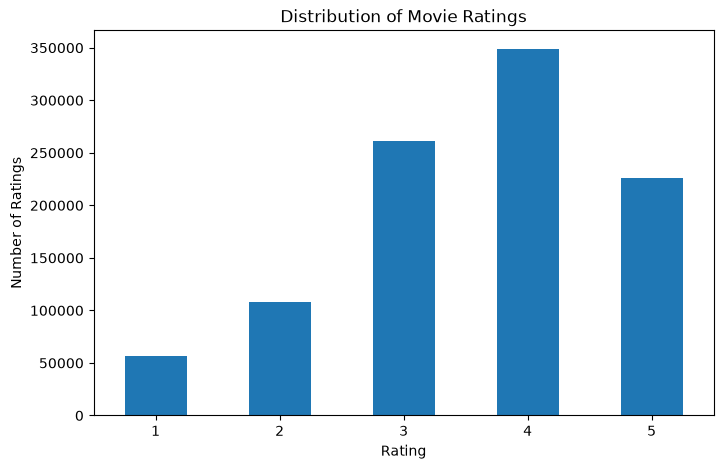

In [14]:
plt.figure(figsize=(8, 5))

rating_counts.plot(kind="bar")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)

plt.show()

In [15]:
print("Mean rating:", ratings["rating"].mean())
print("Median rating:", ratings["rating"].median())
print("Mode rating:", ratings["rating"].mode()[0])

Mean rating: 3.581564453029317
Median rating: 4.0
Mode rating: 4


### Rating Analysis Findings

- The dataset contains 1,000,209 ratings.
- Ratings range from 1 to 5.
- The most common rating is 4, with 348,971 ratings.
- The least common rating is 1, with 56,174 ratings.
- The average rating is approximately 3.58.
- The median and mode rating are both 4.
- Overall, ratings are concentrated toward the higher end of the scale, indicating that users generally give positive ratings.

In [16]:
movie_rating_counts = ratings["movie_id"].value_counts()

movie_rating_counts.head(10)

movie_id
2858    3428
260     2991
1196    2990
1210    2883
480     2672
2028    2653
589     2649
2571    2590
1270    2583
593     2578
Name: count, dtype: int64

In [17]:
top_movies = (
    movie_rating_counts
    .head(10)
    .reset_index()
    .rename(columns={"count": "rating_count"})
)

top_movies = top_movies.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left"
)

top_movies[["movie_id", "title", "rating_count"]]

,movie_id,title,rating_count
0,2858,American Beauty (1999),3428
1,260,Star Wars: Episode IV - A New Hope (1977),2991
2,1196,Star Wars: Episode V - The Empire Strikes Back...,2990
3,1210,Star Wars: Episode VI - Return of the Jedi (1983),2883
4,480,Jurassic Park (1993),2672
5,2028,Saving Private Ryan (1998),2653
6,589,Terminator 2: Judgment Day (1991),2649
7,2571,"Matrix, The (1999)",2590
8,1270,Back to the Future (1985),2583
9,593,"Silence of the Lambs, The (1991)",2578


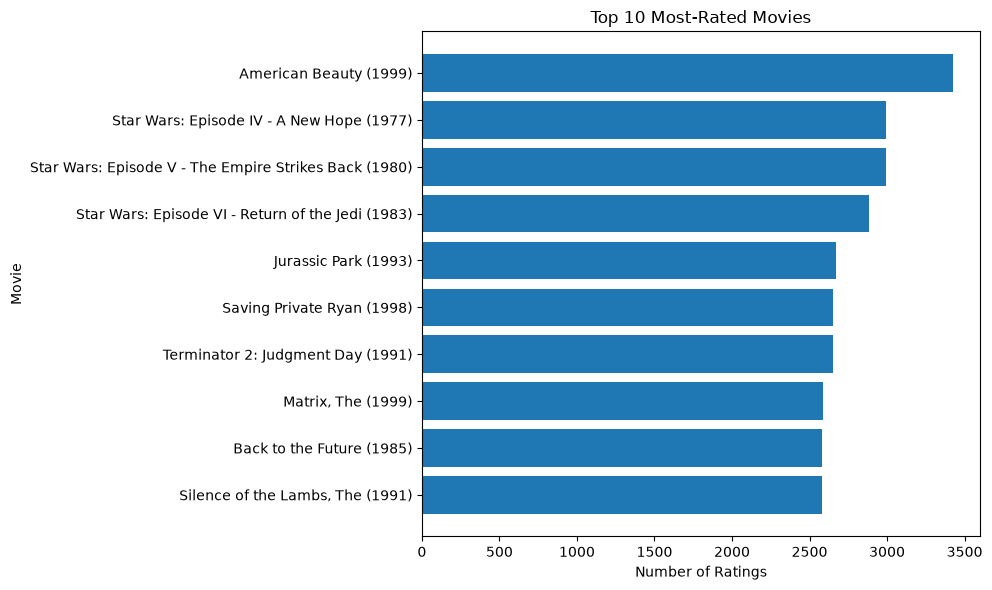

In [18]:
plt.figure(figsize=(10, 6))

plt.barh(top_movies["title"], top_movies["rating_count"])

plt.title("Top 10 Most-Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [19]:
movie_stats = (
    ratings.groupby("movie_id")["rating"]
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={
        "mean": "average_rating",
        "count": "rating_count"
    })
)

movie_stats.head()

,movie_id,average_rating,rating_count
0,1,4.146846,2077
1,2,3.201141,701
2,3,3.016736,478
3,4,2.729412,170
4,5,3.006757,296


In [20]:
movie_stats["rating_count"].describe()

count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
Name: rating_count, dtype: float64

In [21]:
popular_movies = movie_stats[movie_stats["rating_count"] >= 100].copy()

print("Movies with at least 100 ratings:", len(popular_movies))

Movies with at least 100 ratings: 2019


In [22]:
top_rated_movies = (
    popular_movies
    .sort_values("average_rating", ascending=False)
    .head(10)
)

top_rated_movies = top_rated_movies.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left"
)

top_rated_movies[
    ["movie_id", "title", "average_rating", "rating_count"]
]

,movie_id,title,average_rating,rating_count
0,2019,Seven Samurai (The Magnificent Seven) (Shichin...,4.560510,628
1,318,"Shawshank Redemption, The (1994)",4.554558,2227
2,858,"Godfather, The (1972)",4.524966,2223
3,745,"Close Shave, A (1995)",4.520548,657
4,50,"Usual Suspects, The (1995)",4.517106,1783
5,527,Schindler's List (1993),4.510417,2304
6,1148,"Wrong Trousers, The (1993)",4.507937,882
7,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.491489,470
8,1198,Raiders of the Lost Ark (1981),4.477725,2514
9,904,Rear Window (1954),4.476190,1050


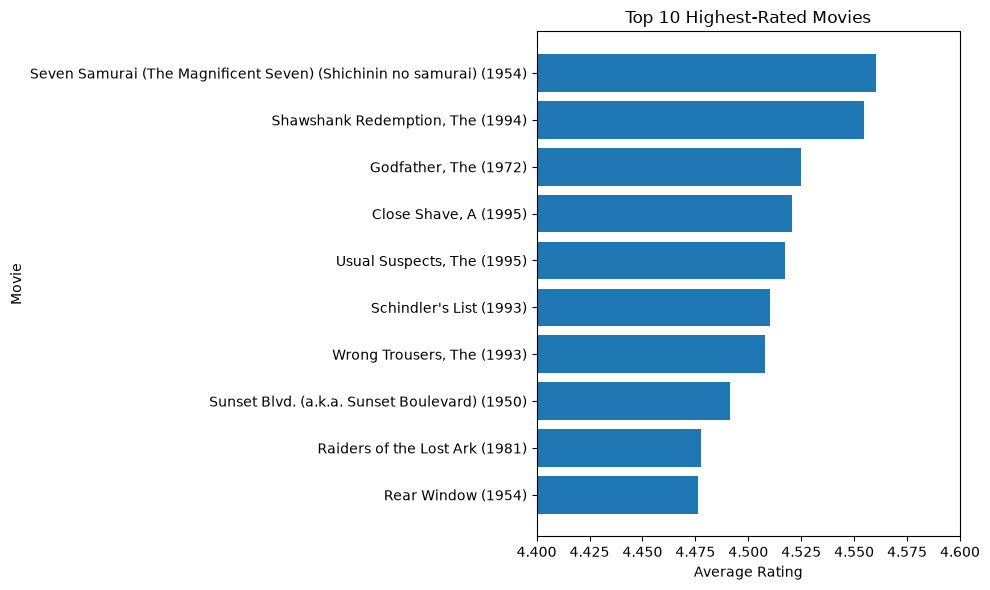

In [23]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_rated_movies["title"],
    top_rated_movies["average_rating"]
)

plt.title("Top 10 Highest-Rated Movies")
plt.xlabel("Average Rating")
plt.ylabel("Movie")

plt.gca().invert_yaxis()
plt.xlim(4.4, 4.6)

plt.tight_layout()
plt.show()

In [24]:
genre_series = movies["genres"].str.split("|").explode()

genre_counts = genre_series.value_counts()

genre_counts

genres
Drama          1603
Comedy         1200
Action          503
Thriller        492
Romance         471
Horror          343
Adventure       283
Sci-Fi          276
Children's      251
Crime           211
War             143
Documentary     127
Musical         114
Mystery         106
Animation       105
Fantasy          68
Western          68
Film-Noir        44
Name: count, dtype: int64

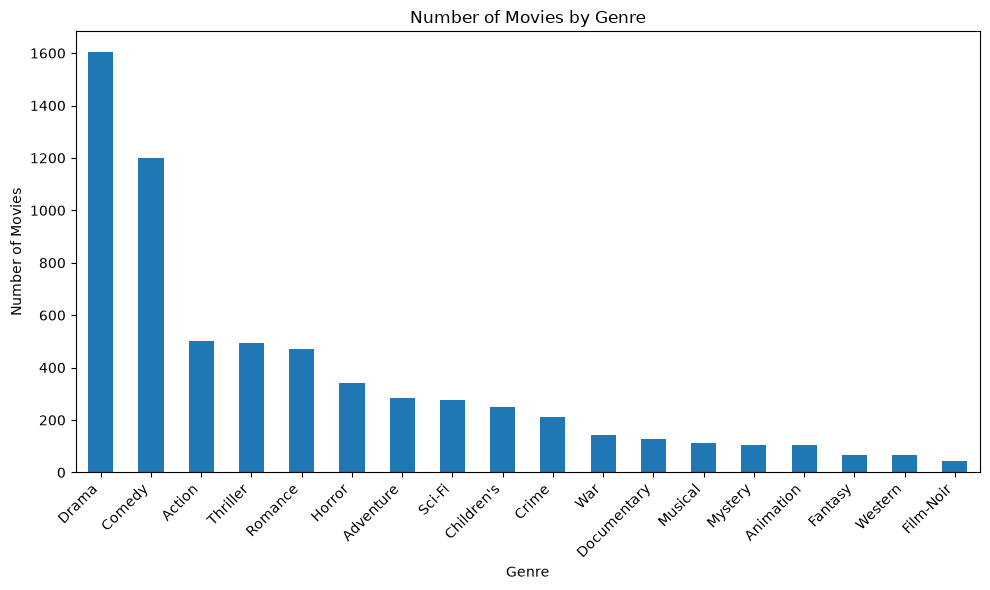

In [25]:
plt.figure(figsize=(10, 6))

genre_counts.plot(kind="bar")

plt.title("Number of Movies by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [26]:
# Analyze the average movie rating for each genre.

movie_genres = movies.copy()

movie_genres["genres"] = movie_genres["genres"].str.split("|")

movie_genres = movie_genres.explode("genres")

genre_ratings = movie_genres.merge(
    ratings,
    on="movie_id",
    how="inner"
)

genre_rating_stats = (
    genre_ratings
    .groupby("genres")["rating"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

genre_rating_stats

,mean,count
genres,,
Film-Noir,4.075188,18261
Documentary,3.933123,7910
War,3.893327,68527
Drama,3.766332,354529
Crime,3.708679,79541
Animation,3.684868,43293
Mystery,3.668102,40178
Musical,3.665519,41533
Western,3.637770,20683


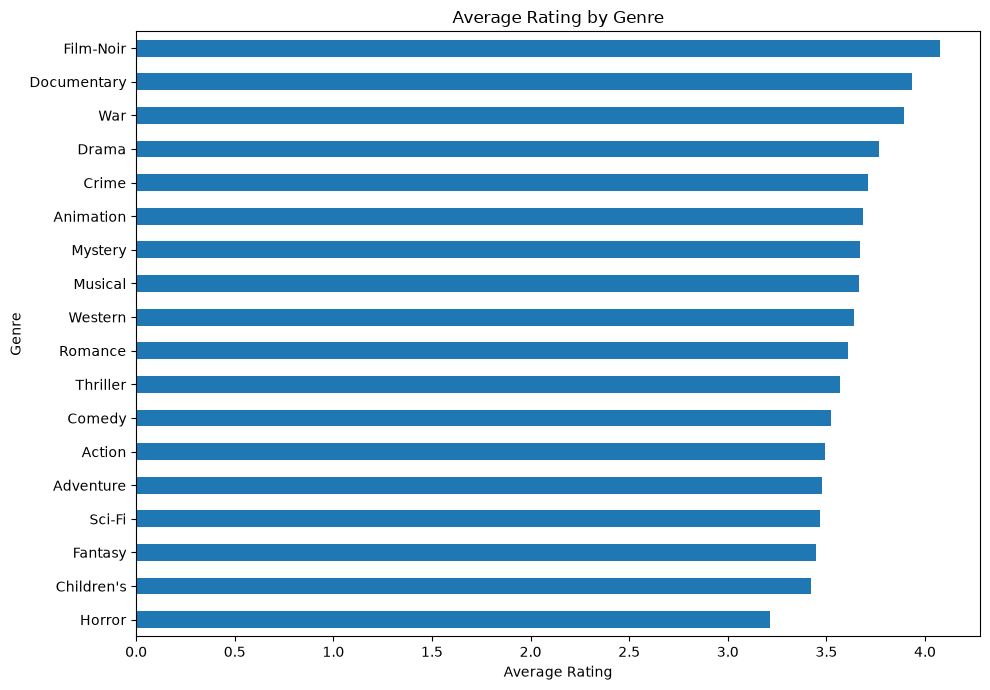

In [27]:
# Visualize the average rating for each genre.

genre_rating_stats["mean"].sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Average Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [28]:
# Analyze the distribution of users by gender.

gender_counts = users["gender"].value_counts()

print(gender_counts)

gender
M    4331
F    1709
Name: count, dtype: int64


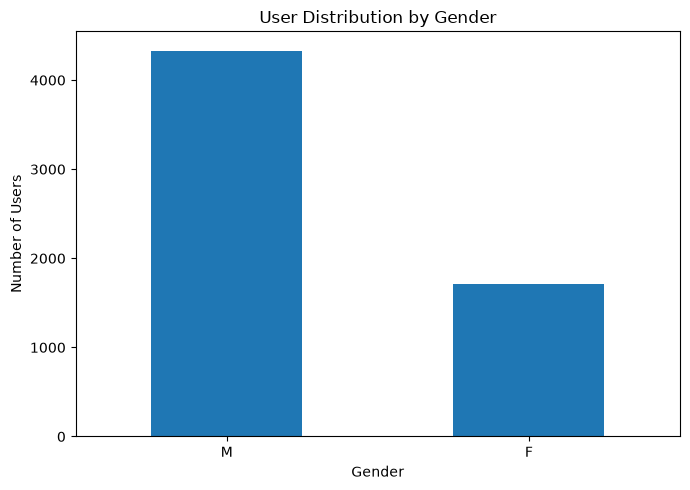

In [29]:
gender_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("User Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Users")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [30]:
# Analyze the age distribution of users.

print(users["age"].describe())

count    6040.000000
mean       30.639238
std        12.895962
min         1.000000
25%        25.000000
50%        25.000000
75%        35.000000
max        56.000000
Name: age, dtype: float64


In [31]:
# Group users into meaningful age categories.

age_bins = [0, 17, 24, 34, 44, 54, 100]
age_labels = ["Under 18", "18-24", "25-34", "35-44", "45-54", "55+"]

users["age_group"] = pd.cut(
    users["age"],
    bins=age_bins,
    labels=age_labels
)

age_group_counts = users["age_group"].value_counts().sort_index()

age_group_counts

age_group
Under 18     222
18-24       1103
25-34       2096
35-44       1193
45-54       1046
55+          380
Name: count, dtype: int64

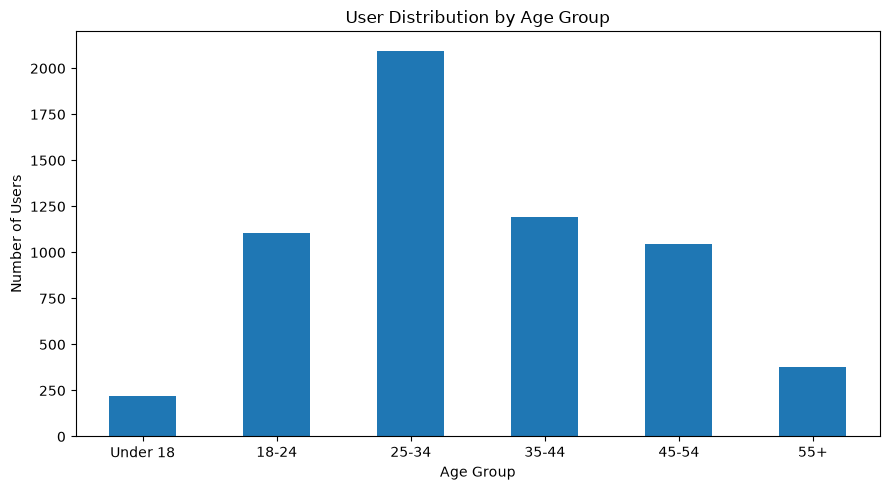

In [32]:
# Visualize the distribution of users across age groups.

age_group_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("User Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Users")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [33]:
# Analyze the distribution of users across occupations.

occupation_counts = users["occupation"].value_counts().sort_index()

print(occupation_counts)

occupation
0     711
1     528
2     267
3     173
4     759
5     112
6     236
7     679
8      17
9      92
10    195
11    129
12    388
13    142
14    302
15    144
16    241
17    502
18     70
19     72
20    281
Name: count, dtype: int64


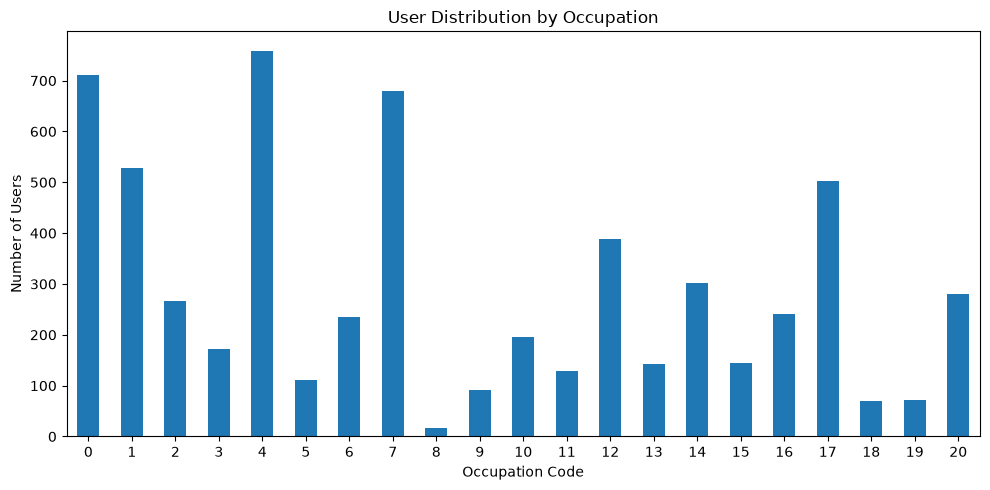

In [34]:
# Visualize the distribution of users across occupation categories.

occupation_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("User Distribution by Occupation")
plt.xlabel("Occupation Code")
plt.ylabel("Number of Users")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [35]:
# Analyze how actively users rate movies.

user_rating_counts = ratings["user_id"].value_counts()

print(user_rating_counts.describe())

count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
Name: count, dtype: float64


In [36]:
# Identify the users who have rated the most movies.

most_active_users = user_rating_counts.head(10)

print(most_active_users)

user_id
4169    2314
1680    1850
4277    1743
1941    1595
1181    1521
889     1518
3618    1344
2063    1323
1150    1302
1015    1286
Name: count, dtype: int64


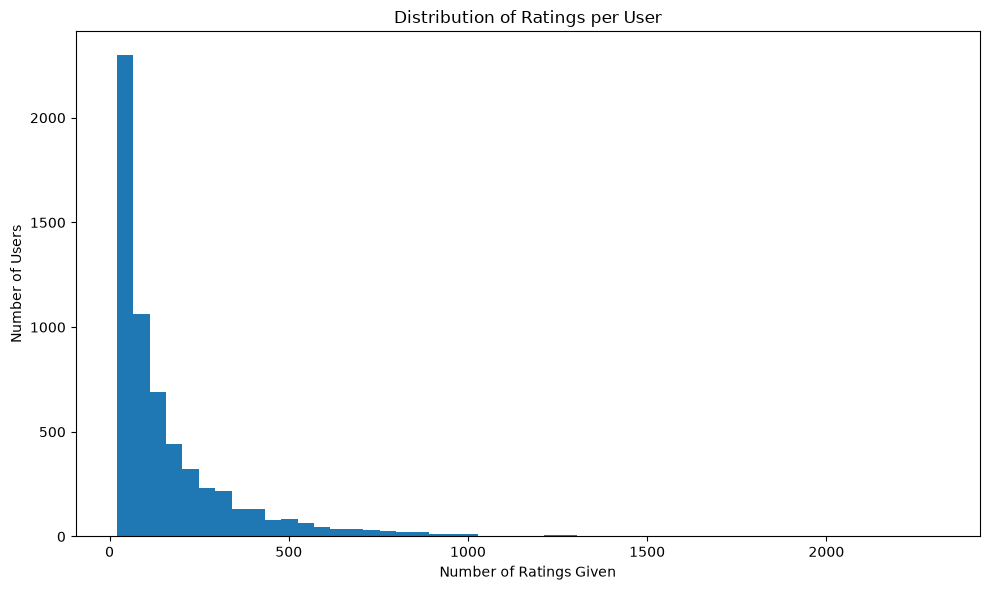

In [37]:
# Visualize the distribution of ratings given by each user.

plt.figure(figsize=(10, 6))

plt.hist(user_rating_counts, bins=50)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings Given")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

### User Activity Analysis Findings

- Users show highly uneven rating activity.
- Most users have given a relatively small number of ratings.
- A small number of users have given hundreds or even thousands of ratings.
- The distribution is strongly right-skewed, with a maximum of 2,314 ratings by a single user.
- This variation in user activity is important for collaborative filtering and handling user preferences.

In [38]:
# Analyze how actively movies are rated by users.

movie_rating_counts = ratings["movie_id"].value_counts()

print(movie_rating_counts.describe())

count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
Name: count, dtype: float64


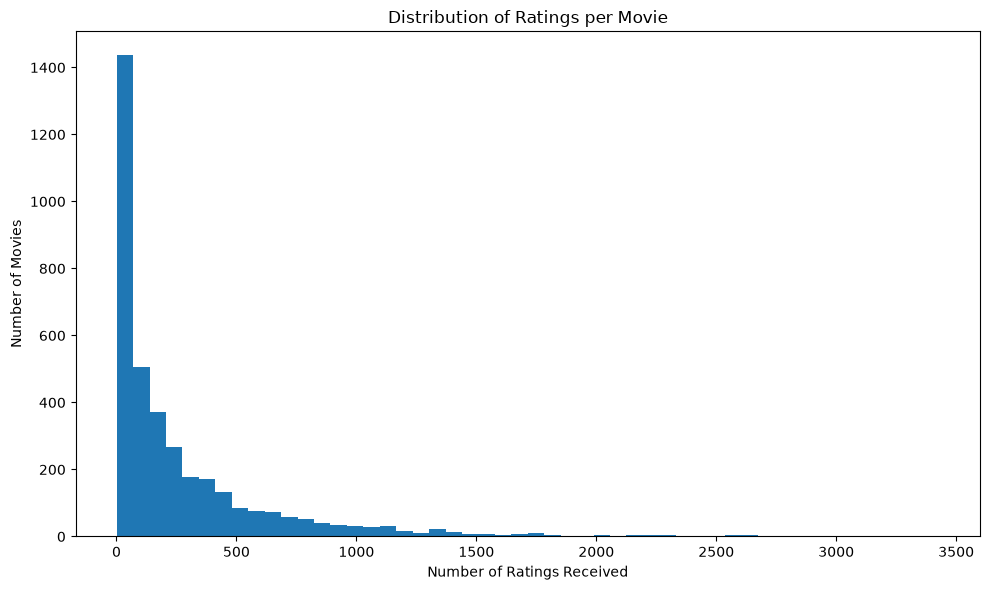

In [39]:
# Visualize the distribution of ratings received by each movie.

plt.figure(figsize=(10, 6))

plt.hist(movie_rating_counts, bins=50)

plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings Received")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

In [40]:
# Identify the movies that have received the most ratings.

most_rated_movies = (
    movie_rating_counts
    .head(10)
    .reset_index()
    .rename(columns={"count": "rating_count"})
)

most_rated_movies = most_rated_movies.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left"
)

most_rated_movies[["movie_id", "title", "rating_count"]]

,movie_id,title,rating_count
0,2858,American Beauty (1999),3428
1,260,Star Wars: Episode IV - A New Hope (1977),2991
2,1196,Star Wars: Episode V - The Empire Strikes Back...,2990
3,1210,Star Wars: Episode VI - Return of the Jedi (1983),2883
4,480,Jurassic Park (1993),2672
5,2028,Saving Private Ryan (1998),2653
6,589,Terminator 2: Judgment Day (1991),2649
7,2571,"Matrix, The (1999)",2590
8,1270,Back to the Future (1985),2583
9,593,"Silence of the Lambs, The (1991)",2578


### Movie Activity Analysis Findings

- Movie popularity varies significantly across the dataset.
- American Beauty (1999) has the highest number of ratings with 3,428.
- Several Star Wars movies are among the most-rated movies.
- The top 10 movies each received more than 2,500 ratings.
- A small number of movies receive a large proportion of the ratings, while many movies have relatively few ratings.
- Movies with more ratings provide more reliable information for building recommendations.

In [42]:
# Analyze the number of unique user-movie interactions.

user_movie_pairs = ratings[["user_id", "movie_id"]].drop_duplicates()

print("Unique user-movie interactions:", len(user_movie_pairs))

Unique user-movie interactions: 1000209


In [43]:
# Measure the sparsity of the user-movie interaction matrix.

num_users = ratings["user_id"].nunique()
num_movies = ratings["movie_id"].nunique()
num_interactions = len(ratings)

total_possible_interactions = num_users * num_movies

sparsity = 1 - (num_interactions / total_possible_interactions)

print("Number of users:", num_users)
print("Number of movies:", num_movies)
print("Total possible interactions:", total_possible_interactions)
print("Actual interactions:", num_interactions)
print("Sparsity:", sparsity)

Number of users: 6040
Number of movies: 3706
Total possible interactions: 22384240
Actual interactions: 1000209
Sparsity: 0.9553163743776871


### User–Movie Interaction and Sparsity Findings

- The dataset contains 6,040 users and 3,706 movies with ratings.
- There are 22,384,240 possible user–movie interactions.
- Only 1,000,209 interactions actually contain ratings.
- The user–movie interaction matrix has approximately 95.53% sparsity.
- Only about 4.47% of possible user–movie combinations have ratings.
- This high sparsity is an important characteristic of the dataset and is a key challenge for collaborative filtering.

In [44]:
# Analyze the time period covered by the movie ratings.

ratings["timestamp"] = pd.to_datetime(ratings["timestamp"], unit="s")

print("First rating:", ratings["timestamp"].min())
print("Last rating:", ratings["timestamp"].max())

First rating: 2000-04-25 23:05:32
Last rating: 2003-02-28 17:49:50
